# 04 — Acuan clear-sky, k_c, dan k_max (T10, T11)

| Bagian | Isi | Checklist |
|---|---|---|
| 1 | Muat data per jam + flag cerah per jam dari data 10 menit | — |
| 2 | Ineichen-Perez pada waktu efektif sampel → agregasi per jam (aturan sama dengan notebook 03) | T10.1–T10.3 |
| 3 | Bandingkan dua acuan pada jam cerah: median k_c, % k_c > 1, tren vs zenit & musim | T10.4 |
| 4 | **Keputusan #3** (acuan clear-sky) | T10.5 |
| 5 | k_c, histogram data latih, **k_max = P99,9** (keputusan #4), cek val/uji | T11.1–T11.4 |
| 6 | Bonus: k_c rata-rata per jam WIB (uji dugaan awan sore) | — |
| 7 | Simpan + tulis ke `config.yaml` | — |

Fungsi `kc()`, `clip()`, `ineichen_hourly()` ada di `src/clearsky.py` (tes: `tests/test_clearsky.py`, T11.5).

## 0. Setup

In [1]:
import io, json, re, sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, yaml

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from clearsky import kc, clip, ineichen_hourly, HOURLY_RULE

CONFIG_PATH = ROOT / "configs" / "config.yaml"
CFG = yaml.safe_load(open(CONFIG_PATH))
RAW, INTERIM, FIG, RES = ROOT / "data/raw", ROOT / "data/interim", ROOT / "figures", ROOT / "results"
QC = json.loads((RES / "qc_summary.json").read_text())

LAT, LON = CFG["location"]["lat"], CFG["location"]["lon"]
ELEV = float(CFG["location"]["elevation_m"])
ZMAX = CFG["physics"]["zenith_max_deg"]
DELTA = int(QC["delta_min"])
SPLIT = CFG["data"]["split"]
INTERP_CODES = [1, 2, 3, 4, 6]
print(f"({LAT}, {LON}) elev {ELEV} m | Δ = {DELTA:+d} menit (dari notebook 03) | split {SPLIT}")

(-6.8899, 107.61) elev 770.0 m | Δ = +1 menit (dari notebook 03) | split {'train': [2016, 2017, 2018], 'val': [2019], 'test': [2020]}


## 1. Data per jam + flag cerah per jam
Jam **cerah** = keenam sampel 10 menit ber-`cloud_type` 0/1 dan `fill_flag` 0 atau 5 (kode 5 = dipotong ke clear-sky, nilainya tetap hasil model).
Seleksi sengaja **tidak** memakai rasio GHI/clear-sky NSRDB, supaya perbandingan dua acuan tidak berat sebelah.

In [2]:
hourly = pd.read_parquet(INTERIM / "nsrdb_hourly.parquet")

def read_nsrdb(p):
    lines = p.read_text().splitlines()
    df = pd.read_csv(io.StringIO("\n".join(lines[2:])))
    df.index = pd.to_datetime(df[["Year", "Month", "Day", "Hour", "Minute"]]).dt.tz_localize("UTC")
    df.columns = [c.strip().lower().replace(" ", "_") for c in df.columns]
    return df[["cloud_type", "fill_flag"]]

raw = pd.concat(read_nsrdb(RAW / f"nsrdb_{y}.csv") for y in CFG["data"]["years"]).sort_index()
raw = raw[~raw.index.duplicated()]
x = raw.copy(); x.index = x.index + pd.Timedelta(minutes=DELTA)

good = x["cloud_type"].isin([0, 1]) & x["fill_flag"].isin([0, 5])
hourly["clear_frac"] = good.resample(**HOURLY_RULE).mean().reindex(hourly.index)
if "interp_frac" not in hourly:
    hourly["interp_frac"] = x["fill_flag"].isin(INTERP_CODES).resample(**HOURLY_RULE).mean().reindex(hourly.index)

day = hourly["solar_zenith_angle"] < ZMAX
clear = day & (hourly["clear_frac"] == 1) & hourly["ghi"].notna()
print(f"{int(day.sum()):,} jam siang | {int(clear.sum()):,} jam cerah ({clear.sum() / day.sum():.1%})")
print("Jam cerah per bulan:", hourly.index[clear].month.value_counts().sort_index().to_dict())

20,831 jam siang | 2,893 jam cerah (13.9%)
Jam cerah per bulan: {1: 63, 2: 47, 3: 87, 4: 142, 5: 314, 6: 366, 7: 513, 8: 626, 9: 419, 10: 196, 11: 92, 12: 28}


## 2. Ineichen-Perez (T10.1–T10.3)
Dihitung pada **waktu efektif tiap sampel 10 menit** (timestamp + Δ), lalu dirata-rata per jam dengan aturan yang sama persis seperti GHI observasi. Dengan begitu bias pusat jam (±4 menit) sama untuk GHI dan GHI_cs dan hilang di k_c.
Linke turbidity: klimatologi bulanan bawaan pvlib (deterministik — tidak memakai data hari target).

In [3]:
ine = ineichen_hourly(raw.index, LAT, LON, ELEV, delta_min=DELTA).reindex(hourly.index)
hourly = hourly.join(ine)
print(hourly[["ghi", "clearsky_ghi", "ineichen_ghi"]].describe().round(1))

           ghi  clearsky_ghi  ineichen_ghi
count  43847.0       43847.0       43847.0
mean     202.6         288.9         293.7
std      279.2         365.5         376.7
min        0.0           0.0           0.0
25%        0.0           0.0           0.0
50%        6.7          18.8           7.4
75%      404.2         631.5         650.0
max     1069.8        1076.8        1051.9


## 3. Bandingkan dua acuan pada jam cerah (T10.4)

In [4]:
REFS = {"nsrdb": "clearsky_ghi", "ineichen": "ineichen_ghi"}
for name, col in REFS.items():
    hourly[f"kc_{name}"] = kc(hourly["ghi"], hourly[col], hourly["solar_zenith_angle"], ZMAX)

c = hourly[clear]
zbins = pd.cut(c["solar_zenith_angle"], [0, 20, 40, 60, 75, ZMAX])
rows = []
for name in REFS:
    k = c[f"kc_{name}"].dropna()
    slope = np.polyfit(c.loc[k.index, "solar_zenith_angle"], k, 1)[0] * 10      # per 10° zenit
    by_z = c.groupby(zbins, observed=True)[f"kc_{name}"].median()
    by_m = c.groupby(c.index.month)[f"kc_{name}"].median()
    rows.append({
        "acuan": name, "n": len(k),
        "median": k.median(), "IQR": k.quantile(.75) - k.quantile(.25),
        "% k_c>1": (k > 1).mean() * 100,
        "tren /10° zenit": slope,
        "rentang median per zenit": by_z.max() - by_z.min(),
        "rentang median per bulan": by_m.max() - by_m.min(),
    })
cmp_tab = pd.DataFrame(rows).set_index("acuan").round(4)
cmp_tab

,n,median,IQR,% k_c>1,tren /10° zenit,rentang median per zenit,rentang median per bulan
acuan,,,,,,,
nsrdb,2893,1.0000,0.0000,0.0000,-0.0000,0.0000,0.0000
ineichen,2893,1.0052,0.0722,55.2022,0.0413,0.3259,0.0249


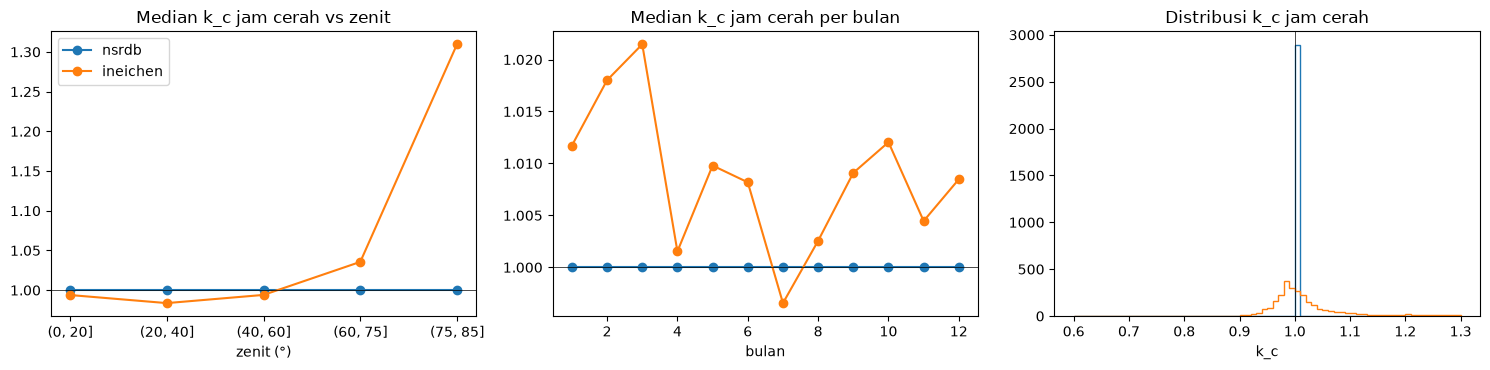

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for name in REFS:
    m = c.groupby(zbins, observed=True)[f"kc_{name}"].median()
    ax[0].plot([str(i) for i in m.index], m.values, marker="o", label=name)
    mm = c.groupby(c.index.month)[f"kc_{name}"].median()
    ax[1].plot(mm.index, mm.values, marker="o", label=name)
    ax[2].hist(c[f"kc_{name}"].dropna(), bins=np.linspace(0.6, 1.3, 71), histtype="step", label=name)
ax[0].set(title="Median k_c jam cerah vs zenit", xlabel="zenit (°)"); ax[0].axhline(1, c="k", lw=.5)
ax[1].set(title="Median k_c jam cerah per bulan", xlabel="bulan"); ax[1].axhline(1, c="k", lw=.5)
ax[2].set(title="Distribusi k_c jam cerah", xlabel="k_c"); ax[2].axvline(1, c="k", lw=.5)
ax[0].legend()
plt.tight_layout(); plt.savefig(FIG / "clearsky_compare.png", dpi=150, bbox_inches="tight"); plt.show()

## 4. Keputusan #3: acuan clear-sky (T10.5)
Kriteria di rencana: median k_c jam cerah paling dekat 1 dan tren terhadap zenit paling kecil. **Tapi dua hal membuat perbandingan ini tidak netral:**

1. **NSRDB menghitung GHI cerah dengan REST2 — model yang sama dengan `clearsky_ghi`-nya — lalu memotong GHI ke `clearsky_ghi` (fill_flag 5).** Jadi k_c NSRDB pada jam cerah ≈ 1 dan ≤ 1 *karena cara datanya dibuat*, bukan karena acuannya lebih akurat.
2. **Kebocoran informasi:** `clearsky_ghi` NSRDB memakai aerosol & uap air reanalisis (MERRA-2) *pada jam target*. Pada jam penerbitan (12.00 WIB D-1) nilai ini belum diketahui. Kalau dipakai untuk normalisasi target atau untuk mengembalikan prediksi k_c → GHI, ramalan diam-diam memakai informasi masa depan. Ineichen dengan Linke klimatologi murni deterministik (T12.2: "deterministik, jadi boleh dipakai").

Karena itu tabel di atas dibaca sebagai **cek bias Ineichen**, bukan lomba. Ineichen dipakai kecuali biasnya besar (median jam cerah di luar 0,90–1,10 atau tren kuat) — dan biasnya cukup dilaporkan sebagai batasan, karena model ML tetap belajar memetakan k_c Ineichen.

In [6]:
ine_row = cmp_tab.loc["ineichen"]
ine_ok = 0.90 <= ine_row["median"] <= 1.10 and abs(ine_row["tren /10° zenit"]) < 0.03
print(f"Ineichen: median {ine_row['median']:.3f}, tren {ine_row['tren /10° zenit']:+.4f}/10°, "
      f"rentang per zenit {ine_row['rentang median per zenit']:.3f}, per bulan {ine_row['rentang median per bulan']:.3f}")
print("Bias Ineichen dalam batas wajar ✓" if ine_ok else "⚠ Bias Ineichen besar — diskusikan sebelum memutuskan")

CLEARSKY_REF = "ineichen"          # ubah hanya bila ada alasan kuat; catat alasannya di decisions.md
CS_COL = REFS[CLEARSKY_REF]
print("Keputusan #3 →", CLEARSKY_REF)

Ineichen: median 1.005, tren +0.0413/10°, rentang per zenit 0.326, per bulan 0.025
⚠ Bias Ineichen besar — diskusikan sebelum memutuskan
Keputusan #3 → ineichen


## 5. k_c dan k_max (T11)
- k_c = GHI / GHI_cs untuk zenit < 85°, malam = NaN (T11.1).
- k_max = **persentil 99,9 k_c siang data latih 2016–2018** (T11.3), dihitung pada jam *valid* (≤ 1/6 sampel interpolasi, keputusan #10) supaya nilai isian NSRDB tidak menentukan batas fisis.
- Val/uji hanya **dilaporkan**, tidak dipakai menyetel ulang (T11.4).

k_max = P99,9 k_c siang latih = 1.5747  (n = 9,759 jam)
  P50: 0.7298
  P90: 1.0060
  P99: 1.3968
  P99.9: 1.5747

k_c latih per rentang zenit — apakah k_max didominasi matahari rendah?


,n,P99_9,pct_di_atas_kmax
solar_zenith_angle,,,
"(0, 40]",4507,1.039,0.000
"(40, 60]",3057,1.062,0.000
"(60, 70]",1293,1.110,0.000
"(70, 75]",512,1.168,0.000
"(75, 80]",77,1.349,0.000
"(80, 85]",313,1.711,3.195


100% dari jam latih dengan k_c > k_max punya zenit ≥ 75°
% jam siang valid dengan k_c > k_max: {'train': 0.102, 'val': 0.243, 'test': 0.176} (latih ≈ 0,1% by definisi)


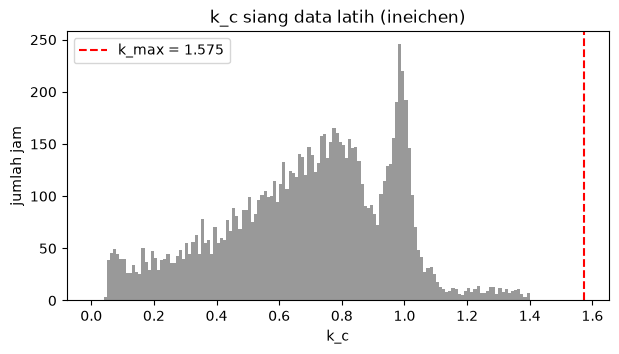

In [7]:
hourly["kc"] = hourly[f"kc_{CLEARSKY_REF}"]
hourly["ghi_cs"] = hourly[CS_COL]
valid = day & (hourly["interp_frac"] <= 1/6 + 1e-9) & hourly["kc"].notna()
yr = hourly.index.year
train = valid & yr.isin(SPLIT["train"])

K_MAX = float(np.nanpercentile(hourly.loc[train, "kc"], 99.9))
print(f"k_max = P99,9 k_c siang latih = {K_MAX:.4f}  (n = {int(train.sum()):,} jam)")
for q in (50, 90, 99, 99.9):
    print(f"  P{q}: {np.nanpercentile(hourly.loc[train, 'kc'], q):.4f}")

zb = pd.cut(hourly.loc[train, "solar_zenith_angle"], [0, 40, 60, 70, 75, 80, ZMAX])
kz = hourly.loc[train, "kc"].groupby(zb, observed=True).agg(
    n="count", P99_9=lambda s: np.nanpercentile(s, 99.9), pct_di_atas_kmax=lambda s: (s > K_MAX).mean() * 100).round(3)
print("\nk_c latih per rentang zenit — apakah k_max didominasi matahari rendah?")
display(kz)
top = hourly.loc[train & (hourly["kc"] > K_MAX), "solar_zenith_angle"]
print(f"{(top >= 75).mean():.0%} dari jam latih dengan k_c > k_max punya zenit ≥ 75°")

over = {}
for name, years in SPLIT.items():
    m = valid & yr.isin(years)
    over[name] = round(float((hourly.loc[m, "kc"] > K_MAX).mean() * 100), 3)
print("% jam siang valid dengan k_c > k_max:", over, "(latih ≈ 0,1% by definisi)")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(hourly.loc[train, "kc"], bins=np.linspace(0, 1.4, 141), color="0.6")
ax.axvline(K_MAX, c="r", ls="--", label=f"k_max = {K_MAX:.3f}")
ax.set(title=f"k_c siang data latih ({CLEARSKY_REF})", xlabel="k_c", ylabel="jumlah jam"); ax.legend()
plt.savefig(FIG / "kc_hist_train.png", dpi=150, bbox_inches="tight"); plt.show()

In [8]:
# Sanity check clip(): pada GHI observasi, clip dengan k_max hanya boleh mengubah ~0,1% jam latih
g = hourly.loc[train, "ghi"].to_numpy(); cs_ = hourly.loc[train, "ghi_cs"].to_numpy()
changed = (clip(g, cs_, K_MAX) != g).mean() * 100
print(f"clip() mengubah {changed:.3f}% jam latih valid")

clip() mengubah 0.102% jam latih valid


In [9]:
import importlib, clearsky
importlib.reload(clearsky)
assert hasattr(clearsky, "kmax_for_zenith"), \
    f"File lama masih terpakai — ganti {clearsky.__file__} dengan clearsky.py versi terbaru"
from clearsky import kmax_for_zenith, clip

# (a) Bias Ineichen tanpa matahari rendah
c75 = c[c["solar_zenith_angle"] < 75]
k75 = c75["kc_ineichen"].dropna()
slope75 = np.polyfit(c75.loc[k75.index, "solar_zenith_angle"], k75, 1)[0] * 10
print(f"Ineichen, jam cerah zenit < 75°: n = {len(k75)}, median {k75.median():.3f}, "
      f"% k_c>1 {(k75 > 1).mean():.1%}, tren {slope75:+.4f}/10°")

# (b) k_max per rentang zenit (P99,9 jam siang valid data latih), dipaksa monoton naik
EDGES = [0, 40, 60, 70, 75, ZMAX]
zt, kt = hourly.loc[train, "solar_zenith_angle"], hourly.loc[train, "kc"]
VALS = [float(np.nanpercentile(kt[(zt > lo) & (zt <= hi)], 99.9)) for lo, hi in zip(EDGES[:-1], EDGES[1:])]
VALS = [round(float(v), 4) for v in np.maximum.accumulate(VALS)]
NS = [int(((zt > lo) & (zt <= hi)).sum()) for lo, hi in zip(EDGES[:-1], EDGES[1:])]
print("\nk_max(z):")
for lo, hi, v, n in zip(EDGES[:-1], EDGES[1:], VALS, NS):
    print(f"  ({lo:>2}, {hi}]°  k_max = {v:.4f}   n = {n}")

hourly["k_max_z"] = kmax_for_zenith(hourly["solar_zenith_angle"], EDGES, VALS)
over_z = {}
for name, ys in SPLIT.items():
    m = valid & yr.isin(ys)
    over_z[name] = round(float((hourly.loc[m, "kc"] > hourly.loc[m, "k_max_z"]).mean() * 100), 3)
print("% jam siang valid dengan k_c > k_max(z):", over_z)

mid = valid & (hourly["solar_zenith_angle"] < 60)
print(f"Jam siang zenit < 60°: k_c > k_max global = {(hourly.loc[mid, 'kc'] > K_MAX).mean():.3%} | "
      f"k_c > k_max(z) = {(hourly.loc[mid, 'kc'] > hourly.loc[mid, 'k_max_z']).mean():.3%}")

# (c) Tulis ke config.yaml (k_max global tetap disimpan sebagai pembanding)
txt = CONFIG_PATH.read_text()
line = f"  k_max_by_zenith: {{edges: {EDGES}, values: {VALS}}}\n"
if "k_max_by_zenith" in txt:
    txt = re.sub(r"  k_max_by_zenith:.*\n", line, txt)
else:
    txt = re.sub(r"(  k_max:.*\n)", lambda m_: m_.group(1) + line, txt, count=1)
CONFIG_PATH.write_text(txt)
print("\nconfig.yaml →", line.strip())
print("cek:", yaml.safe_load(txt)["physics"]["k_max_by_zenith"])

Ineichen, jam cerah zenit < 75°: n = 2409, median 0.997, % k_c>1 46.3%, tren +0.0100/10°

k_max(z):
  ( 0, 40]°  k_max = 1.0389   n = 4507
  (40, 60]°  k_max = 1.0621   n = 3057
  (60, 70]°  k_max = 1.1103   n = 1293
  (70, 75]°  k_max = 1.1685   n = 512
  (75, 85]°  k_max = 1.7094   n = 390
% jam siang valid dengan k_c > k_max(z): {'train': 0.133, 'val': 0.213, 'test': 0.029}
Jam siang zenit < 60°: k_c > k_max global = 0.000% | k_c > k_max(z) = 0.110%

config.yaml → k_max_by_zenith: {edges: [0, 40, 60, 70, 75, 85], values: [1.0389, 1.0621, 1.1103, 1.1685, 1.7094]}
cek: {'edges': [0, 40, 60, 70, 75, 85], 'values': [1.0389, 1.0621, 1.1103, 1.1685, 1.7094]}


## 6. Bonus: k_c rata-rata per jam WIB — uji dugaan awan konvektif sore

,mean,median,count
jam WIB (period-ending),,,
7,1.270,1.266,550
8,0.833,0.901,1708
9,0.816,0.863,1669
10,0.807,0.836,1362
11,0.760,0.786,1467
12,0.707,0.723,1496
13,0.656,0.668,1616
14,0.619,0.636,1692
15,0.586,0.621,1775


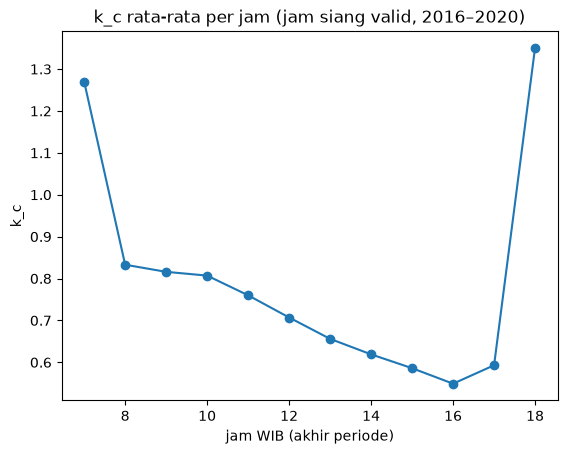

k_c pagi (08–11) = 0.804 vs sore (13–16) = 0.602 → sore lebih berawan ✓ (menjelaskan asimetri T09.3)


In [10]:
wib = (hourly.index.hour + 7) % 24
diurnal = hourly[valid].groupby(wib[valid])["kc"].agg(["mean", "median", "count"]).round(3)
diurnal.index.name = "jam WIB (period-ending)"
display(diurnal)
ax = diurnal["mean"].plot(marker="o", title="k_c rata-rata per jam (jam siang valid, 2016–2020)")
ax.set_xlabel("jam WIB (akhir periode)"); ax.set_ylabel("k_c")
plt.savefig(FIG / "kc_diurnal.png", dpi=150, bbox_inches="tight"); plt.show()
am = diurnal.loc[[h for h in diurnal.index if 8 <= h <= 11], "mean"].mean()
pm = diurnal.loc[[h for h in diurnal.index if 13 <= h <= 16], "mean"].mean()
print(f"k_c pagi (08–11) = {am:.3f} vs sore (13–16) = {pm:.3f} →",
      "sore lebih berawan ✓ (menjelaskan asimetri T09.3)" if am - pm > 0.03 else "tidak ada beda jelas")

## 7. Simpan

In [11]:
cols = ["ghi", "clearsky_ghi", "ineichen_ghi", "ghi_cs", "kc", "kc_nsrdb", "kc_ineichen",
        "solar_zenith_angle", "clear_frac", "interp_frac"]
cols = [c_ for c_ in cols if c_ in hourly] + [c_ for c_ in hourly.columns if c_ not in cols]
hourly[cols].to_parquet(INTERIM / "nsrdb_hourly_kc.parquet")
cmp_tab.to_csv(RES / "clearsky_compare.csv"); diurnal.to_csv(RES / "kc_diurnal.csv")

txt = CONFIG_PATH.read_text()
txt = re.sub(r"k_max:\s*\S+", f"k_max: {K_MAX:.4f}", txt, count=1)
txt = re.sub(r"clearsky_ref:\s*\S+", f'clearsky_ref: "{CLEARSKY_REF}"', txt, count=1)
CONFIG_PATH.write_text(txt)
print("config.yaml →", re.findall(r"(k_max: .*|clearsky_ref: .*)", txt))

r = cmp_tab.loc[CLEARSKY_REF]
print(f"""
Salin ke decisions.md:
- {pd.Timestamp.today():%Y-%m-%d} | Keputusan #3: acuan clear-sky = {CLEARSKY_REF} | ineichen / nsrdb | NSRDB GHI cerah = REST2 = clearsky_ghi dan dipotong ke clearsky_ghi (k_c≤1 by konstruksi); clearsky_ghi NSRDB memakai aerosol/uap air MERRA-2 jam target (tidak tersedia saat penerbitan). Bias Ineichen pada {int(r['n'])} jam cerah: median k_c {r['median']:.3f}, % k_c>1 {r['% k_c>1']:.1f}%, tren {r['tren /10° zenit']:+.4f}/10° zenit | figures/clearsky_compare.png | Bab III.1.5
- {pd.Timestamp.today():%Y-%m-%d} | Keputusan #4: k_max = {K_MAX:.4f} (P99,9 k_c siang valid latih 2016–2018, n={int(train.sum())}); % jam > k_max: {over} | figures/kc_hist_train.png | Bab III.1.5, T29""")

config.yaml → ['k_max: 1.5747                # P99,9 k_c siang data latih (T11)', 'clearsky_ref: "ineichen"         # "ineichen" | "nsrdb" (T10)']

Salin ke decisions.md:
- 2026-11-27 | Keputusan #3: acuan clear-sky = ineichen | ineichen / nsrdb | NSRDB GHI cerah = REST2 = clearsky_ghi dan dipotong ke clearsky_ghi (k_c≤1 by konstruksi); clearsky_ghi NSRDB memakai aerosol/uap air MERRA-2 jam target (tidak tersedia saat penerbitan). Bias Ineichen pada 2893 jam cerah: median k_c 1.005, % k_c>1 55.2%, tren +0.0413/10° zenit | figures/clearsky_compare.png | Bab III.1.5
- 2026-11-27 | Keputusan #4: k_max = 1.5747 (P99,9 k_c siang valid latih 2016–2018, n=9759); % jam > k_max: {'train': 0.102, 'val': 0.243, 'test': 0.176} | figures/kc_hist_train.png | Bab III.1.5, T29
